In [ ]:
import sys
import logging
from pathlib import Path

# prediction lib
PROJECT_SRC_PATH = '/p/projects/eubucco/ufo-prediction/src'
sys.path.append(PROJECT_SRC_PATH)

# project libs
import dataset
from prediction_type import TypeClassifier
from prediction_floors import FloorsPredictor
from prediction_height import HeightPredictor
import preprocessing as pp

# external libs
import numpy as np
import pandas as pd
import geopandas as gpd
import seaborn as sns
import matplotlib.pyplot as plt
from shapely import wkt
import shap
from xgboost import XGBRegressor, XGBClassifier

%load_ext autoreload
%autoreload 2

/home/floriann/.conda/envs/uf-ml/lib/python3.8/site-packages/geopandas/_compat.py:124: UserWarning: The Shapely GEOS version (3.11.4-CAPI-1.17.4) is incompatible with the GEOS version PyGEOS was compiled with (3.10.1-CAPI-1.16.0). Conversions between both will be slow.
  warnings.warn(
/home/floriann/.conda/envs/uf-ml/lib/python3.8/site-packages/shap/utils/_clustering.py:35: NumbaDeprecationWarning: The 'nopython' keyword argument was not supplied to the 'numba.jit' decorator. The implicit default value for this argument is currently False, but it will be changed to True in Numba 0.59.0. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.
  def _pt_shuffle_rec(i, indexes, index_mask, partition_tree, M, pos):
/home/floriann/.conda/envs/uf-ml/lib/python3.8/site-packages/shap/utils/_clustering.py:54: NumbaDeprecationWarning: The 'nopython' keyword argument was not supplied to the 'numba.jit' decor

In [3]:
import sys
print(sys.executable)

/home/floriann/.conda/envs/uf-ml/bin/python


In [ ]:
pd.set_option("display.max_columns", None)

logging.basicConfig(format='%(asctime)s | %(levelname)s : %(message)s', level=logging.INFO)

In [ ]:
XGBOOST_PARAMS = {
    'tree_method': 'hist',
    'device': 'cuda',
    'enable_categorical': True
}
REG_HYPERPARAMETERS = {
    'max_depth': 11,
    'learning_rate': 0.05,
    'n_estimators': 300,
    'colsample_bytree': 0.9,
    'colsample_bylevel': 0.5,
}
CLASS_HYPERPARAMETERS = {
    'max_depth': 11,
    'learning_rate': 0.2,
    'n_estimators': 250,
    'colsample_bytree': 0.9,
    'colsample_bylevel': 0.5,
}


## EU-wide model with samples from everywhere

In [49]:
attr_cov_countries = pd.read_csv('/p/projects/eubucco/data/overview-metrics/nuts3-attribute-coverage-4-merged-dataset-ml-cleaned.csv', index_col=0)
attr_cov_countries['age_coverage'] = attr_cov_countries['age'] / attr_cov_countries['n']
attr_cov_countries[attr_cov_countries.index.str.startswith('IT') & attr_cov_countries['age_coverage'].between(0.001, 0.1)].sort_values(by='age')
# attr_cov_countries[attr_cov_countries.index.str.startswith('IT')]['age_coverage'].hist()

,height,floors,age,type,residential_type,osm_height_merged,osm_floors_merged,osm_age_merged,osm_type_merged,osm_residential_type_merged,height_combined,floors_combined,age_combined,type_combined,residential_type_combined,n,age_coverage


In [57]:
data_path = Path('/p/projects/eubucco/data/5-feature-engineering')
nuts3_ids = pd.read_csv('/p/projects/eubucco/data/0-raw-data/lau/lau_nuts_extra.csv')['NUTS_ID_3'].unique().tolist()

dfs = []
for nuts_id in nuts3_ids:
    try:
        path = data_path / f'{nuts_id}.parquet'
        df = pd.read_parquet(path, columns=dataset.AGE_SPECIFIC_FEATURES + ['age', 'LAU_ID', 'id', 'dataset', 'validation']).dropna(subset=['age'])
        df['NUTS_ID'] = nuts_id
        dfs.append(df.sample(min(10000, int(len(df) / 10))))

    except Exception as e:
        print(f"Error processing file {path}: {e}")

df = pd.concat(dfs)
df.to_parquet(data_path / 'age_generalization_dataset_eu_wide.parquet')

In [9]:
import pyarrow.parquet as pq


data_path = Path('/p/projects/eubucco/data/5-feature-engineering')
nuts3_ids = pd.read_csv('/p/projects/eubucco/data/0-raw-data/lau/lau_nuts_extra.csv')['NUTS_ID_3'].unique().tolist()

dfs = []
for nuts_id in nuts3_ids:
    try:
        path = data_path / f'{nuts_id}.parquet'
        cols = dataset.FEATURES_RES_TYPE + dataset.FEATURES_RES_TYPE_LOCAL + ['residential_type', 'type_source', 'LAU_ID', 'id', 'dataset', 'validation']
        cols_avail = pq.ParquetFile(path).schema.names
        cols = list(set(cols).intersection(set(cols_avail)))
        df = pd.read_parquet(path, columns=cols).dropna(subset=['residential_type'])
        df['NUTS_ID'] = nuts_id
        dfs.append(df.sample(min(10000, int(len(df) / 10))))

    except Exception as e:
        print(f"Error processing file {path}: {e}")

df = pd.concat(dfs)
df.to_parquet(data_path / 'residential_type_generalization_dataset_eu_wide.parquet')

In [61]:
import pyarrow.parquet as pq


data_path = Path('/p/projects/eubucco/data/5-feature-engineering')
nuts3_ids = pd.read_csv('/p/projects/eubucco/data/0-raw-data/lau/lau_nuts_extra.csv')['NUTS_ID_3'].unique().tolist()

dfs = []
for nuts_id in nuts3_ids:
    try:
        path = data_path / f'{nuts_id}.parquet'
        cols = dataset.FEATURES_TYPE + dataset.FEATURES_TYPE_LOCAL + FEATURES_TYPE_CANDIDATES + ['type', 'type_source', 'LAU_ID', 'id', 'dataset', 'validation']
        cols_avail = pq.ParquetFile(path).schema.names
        cols = list(set(cols).intersection(set(cols_avail)))
        df = pd.read_parquet(path, columns=cols).dropna(subset=['type'])
        df['NUTS_ID'] = nuts_id
        dfs.append(df.sample(min(10000, int(len(df) / 10))))

    except Exception as e:
        print(f"Error processing file {path}: {e}")

df = pd.concat(dfs)
df.to_parquet(data_path / 'type_generalization_dataset_eu_wide.parquet')

In [ ]:
import pyarrow.parquet as pq


data_path = Path('/p/projects/eubucco/data/5-feature-engineering')
nuts3_ids = pd.read_csv('/p/projects/eubucco/data/0-raw-data/lau/lau_nuts_extra.csv')['NUTS_ID_3'].unique().tolist()

dfs = []
for nuts_id in nuts3_ids:
    try:
        path = data_path / f'{nuts_id}.parquet'
        cols = dataset.FEATURES_HEIGHT + ['height', 'floors', 'LAU_ID', 'id', 'dataset', 'validation']
        cols_avail = pq.ParquetFile(path).schema.names
        cols = list(set(cols).intersection(set(cols_avail)))
        df = pd.read_parquet(path, columns=cols).dropna(subset=['height'])
        df['NUTS_ID'] = nuts_id
        dfs.append(df.sample(min(10000, int(len(df) / 10))))

    except Exception as e:
        print(f"Error processing file {path}: {e}")

df = pd.concat(dfs)
df.to_parquet(data_path / 'height_generalization_dataset_eu_wide.parquet')

In [ ]:
import pyarrow.parquet as pq


data_path = Path('/p/projects/eubucco/data/5-feature-engineering')
nuts3_ids = pd.read_csv('/p/projects/eubucco/data/0-raw-data/lau/lau_nuts_extra.csv')['NUTS_ID_3'].unique().tolist()

dfs = []
for nuts_id in nuts3_ids:
    try:
        path = data_path / f'{nuts_id}.parquet'
        cols = dataset.FEATURES_FLOORS + ['floors', 'LAU_ID', 'id', 'dataset', 'validation']
        cols_avail = pq.ParquetFile(path).schema.names
        cols = list(set(cols).intersection(set(cols_avail)))
        df = pd.read_parquet(path, columns=cols).dropna(subset=['floors'])
        df['NUTS_ID'] = nuts_id
        dfs.append(df.sample(min(10000, int(len(df) / 10))))

    except Exception as e:
        print(f"Error processing file {path}: {e}")

df = pd.concat(dfs)

# downsample height coverage (afterwards only ~35%)
df = pd.concat([df[df['height'].isna()], df[df['height'].notna()].sample(frac=0.5, random_state=42)])
df.to_parquet('/p/projects/eubucco/data/5-feature-engineering-extra/floors_generalization_dataset_eu_wide.parquet')

In [16]:
# df = pd.read_parquet('/p/projects/eubucco/data/7-release/DE24.parquet', columns=['geometry_source', 'geometry_source_id', 'height_source', 'height_source_ids'])
df[df['height_source'] != 'estimated']
# df[(df['geometry_source'] != df['height_source']) & (df['height_source'] != 'estimated')]
# df[df['height_source_ids'].notna()]

,geometry_source,geometry_source_id,height_source,height_source_ids
92,osm,bayern-latest_5575153,osm,None
515,osm,bayern-latest_5560781,osm,None
520,osm,bayern-latest_5610251,osm,None
548,osm,bayern-latest_1247473,osm,None
934,osm,bayern-latest_5819210,osm,None
...,...,...,...,...
1083359,gov-germany-bavaria,DEBY_LOD2_106056109,gov-germany-bavaria,None
1083360,gov-germany-bavaria,DEBY_LOD2_107897887,gov-germany-bavaria,None
1083361,gov-germany-bavaria,DEBY_LOD2_107897891,gov-germany-bavaria,None
1083362,gov-germany-bavaria,DEBY_LOD2_5828288,gov-germany-bavaria,None


## EU-wide type estimation

In [19]:
def ft_gain(model):
    feature_accuracy_contribution = model.get_booster().get_score(importance_type="gain")
    feature_importance = pd.DataFrame({'importance': feature_accuracy_contribution})
    feature_importance['importance'] = feature_importance['importance'] / feature_importance['importance'].sum()
    return feature_importance.sort_values(by=['importance'], ascending=False)

In [15]:
data_path = Path('/p/projects/eubucco/data/5-feature-engineering')
df = pd.read_parquet(data_path / 'type_generalization_dataset_eu_wide.parquet')

Training model with seed 0...
['residential', 'commercial', 'industrial', 'agricultural', 'public', 'others']


2026-01-23 04:23:24,728 | INFO : Dataset length original: 1275055
2026-01-23 04:23:24,952 | INFO : Dataset length after dropping duplicates: 303819
2026-01-23 04:23:25,065 | INFO : Dataset length after dropping NaNs: 303819
2026-01-23 04:23:25,070 | INFO : Dataset allocated memory: 545 MB
2026-01-23 04:23:25,174 | INFO : Dataset length after dropping building types excluded from classification: 303819
2026-01-23 04:23:25,179 | INFO : Dataset allocated memory: 545 MB
2026-01-23 04:23:25,315 | INFO : No abort signal received. Continuing... To abort please create /p/projects/eubucco/ufo-prediction/metadata/6445160-af8e9d2d.abort.
2026-01-23 04:23:25,316 | INFO : Training dataset length: 242631
2026-01-23 04:23:25,316 | INFO : Test dataset length: 61188
2026-01-23 04:23:25,961 | WARNING : Missing columns {'satclip_pc1', 'nuts_coast_type', 'block_diff_std_orientation'}. Proceeding with available columns.
2026-01-23 04:23:26,058 | INFO : Training dataset length after preprocessing: 242631
20

Classification report:
               precision    recall  f1-score  support
residential    0.913454  0.900328  0.906844    30480
commercial     0.754280  0.789824  0.771643     9316
industrial     0.585181  0.524390  0.553121     2214
agricultural   0.663483  0.679517  0.671404     3476
public         0.576244  0.350586  0.435944     1024
others         0.804322  0.834242  0.819009    14678
accuracy       0.832304  0.832304  0.832304        0
macro avg      0.716161  0.679814  0.692994    61188
weighted avg   0.831319  0.832304  0.831134    61188
Cohen’s kappa: 0.7485
Matthews correlation coefficient (MCC): 0.7486
Training model with seed 1...
['residential', 'commercial', 'industrial', 'agricultural', 'public', 'others']


2026-01-23 04:25:19,453 | INFO : Dataset length original: 1265011
2026-01-23 04:25:19,675 | INFO : Dataset length after dropping duplicates: 305820
2026-01-23 04:25:19,788 | INFO : Dataset length after dropping NaNs: 305820
2026-01-23 04:25:19,793 | INFO : Dataset allocated memory: 549 MB
2026-01-23 04:25:19,904 | INFO : Dataset length after dropping building types excluded from classification: 305820
2026-01-23 04:25:19,909 | INFO : Dataset allocated memory: 549 MB
2026-01-23 04:25:20,060 | INFO : No abort signal received. Continuing... To abort please create /p/projects/eubucco/ufo-prediction/metadata/6445160-98dd8b8e.abort.
2026-01-23 04:25:20,061 | INFO : Training dataset length: 244704
2026-01-23 04:25:20,061 | INFO : Test dataset length: 61116
2026-01-23 04:25:20,697 | WARNING : Missing columns {'satclip_pc1', 'nuts_coast_type', 'block_diff_std_orientation'}. Proceeding with available columns.
2026-01-23 04:25:20,787 | INFO : Training dataset length after preprocessing: 244704
20

Classification report:
               precision    recall  f1-score  support
residential    0.917751  0.905819  0.911746    30845
commercial     0.748500  0.792220  0.769740     8663
industrial     0.596723  0.522202  0.556981     2162
agricultural   0.669477  0.670042  0.669760     3555
public         0.636667  0.360038  0.459964     1061
others         0.801786  0.835469  0.818281    14830
accuracy       0.835886  0.835886  0.835886        0
macro avg      0.728484  0.680965  0.697745    61116
weighted avg   0.834943  0.835886  0.834468    61116
Cohen’s kappa: 0.7518
Matthews correlation coefficient (MCC): 0.7520
Training model with seed 2...
['residential', 'commercial', 'industrial', 'agricultural', 'public', 'others']


...

2026-01-23 04:39:04,382 | INFO : Dataset length original: 1359810
2026-01-23 04:39:04,611 | INFO : Dataset length after dropping duplicates: 309114
2026-01-23 04:39:04,736 | INFO : Dataset length after dropping NaNs: 309114
2026-01-23 04:39:04,741 | INFO : Dataset allocated memory: 555 MB
2026-01-23 04:39:04,852 | INFO : Dataset length after dropping building types excluded from classification: 309114
2026-01-23 04:39:04,857 | INFO : Dataset allocated memory: 555 MB
2026-01-23 04:39:04,999 | INFO : No abort signal received. Continuing... To abort please create /p/projects/eubucco/ufo-prediction/metadata/6445160-1a1748bd.abort.
2026-01-23 04:39:04,999 | INFO : Training dataset length: 247130
2026-01-23 04:39:05,000 | INFO : Test dataset length: 61984
2026-01-23 04:39:05,655 | WARNING : Missing columns {'satclip_pc1', 'nuts_coast_type', 'block_diff_std_orientation'}. Proceeding with available columns.
2026-01-23 04:39:05,749 | INFO : Training dataset length after preprocessing: 247130
20

Classification report:
               precision    recall  f1-score  support
residential    0.917344  0.901232  0.909216    30688
commercial     0.737368  0.769611  0.753145     9102
industrial     0.583249  0.531494  0.556170     2175
agricultural   0.659738  0.684288  0.671789     3386
public         0.689890  0.523871  0.595526     1550
others         0.799796  0.830604  0.814909    15083
accuracy       0.830456  0.830456  0.830456        0
macro avg      0.731231  0.706850  0.716793    61984
weighted avg   0.830828  0.830456  0.830147    61984
Cohen’s kappa: 0.7471
Matthews correlation coefficient (MCC): 0.7473
Training model with seed 9...
['residential', 'commercial', 'industrial', 'agricultural', 'public', 'others']


2026-01-23 04:41:02,857 | INFO : Dataset length original: 1328981
2026-01-23 04:41:03,093 | INFO : Dataset length after dropping duplicates: 320785
2026-01-23 04:41:03,208 | INFO : Dataset length after dropping NaNs: 320785
2026-01-23 04:41:03,215 | INFO : Dataset allocated memory: 576 MB
2026-01-23 04:41:03,330 | INFO : Dataset length after dropping building types excluded from classification: 320785
2026-01-23 04:41:03,335 | INFO : Dataset allocated memory: 576 MB
2026-01-23 04:41:03,492 | INFO : No abort signal received. Continuing... To abort please create /p/projects/eubucco/ufo-prediction/metadata/6445160-2effa03a.abort.
2026-01-23 04:41:03,492 | INFO : Training dataset length: 256591
2026-01-23 04:41:03,492 | INFO : Test dataset length: 64194
2026-01-23 04:41:04,154 | WARNING : Missing columns {'satclip_pc1', 'nuts_coast_type', 'block_diff_std_orientation'}. Proceeding with available columns.
2026-01-23 04:41:04,269 | INFO : Training dataset length after preprocessing: 256591
20

Classification report:
               precision    recall  f1-score  support
residential    0.914534  0.900985  0.907709    32601
commercial     0.748087  0.785337  0.766260     8716
industrial     0.607107  0.529001  0.565369     2293
agricultural   0.654217  0.666270  0.660188     3365
public         0.578947  0.360656  0.444444     1220
others         0.806344  0.843740  0.824618    15999
accuracy       0.835156  0.835156  0.835156        0
macro avg      0.718206  0.680998  0.694765    64194
weighted avg   0.833966  0.835156  0.833787    64194
Cohen’s kappa: 0.7493
Matthews correlation coefficient (MCC): 0.7494
Classification report:
               precision    recall  f1-score  support
residential    0.914534  0.900985  0.907709    32601
commercial     0.748087  0.785337  0.766260     8716
industrial     0.607107  0.529001  0.565369     2293
agricultural   0.654217  0.666270  0.660188     3365
public         0.578947  0.360656  0.444444     1220
others         0.806344  0.843740  

FixedFormatter should only be used together with FixedLocator


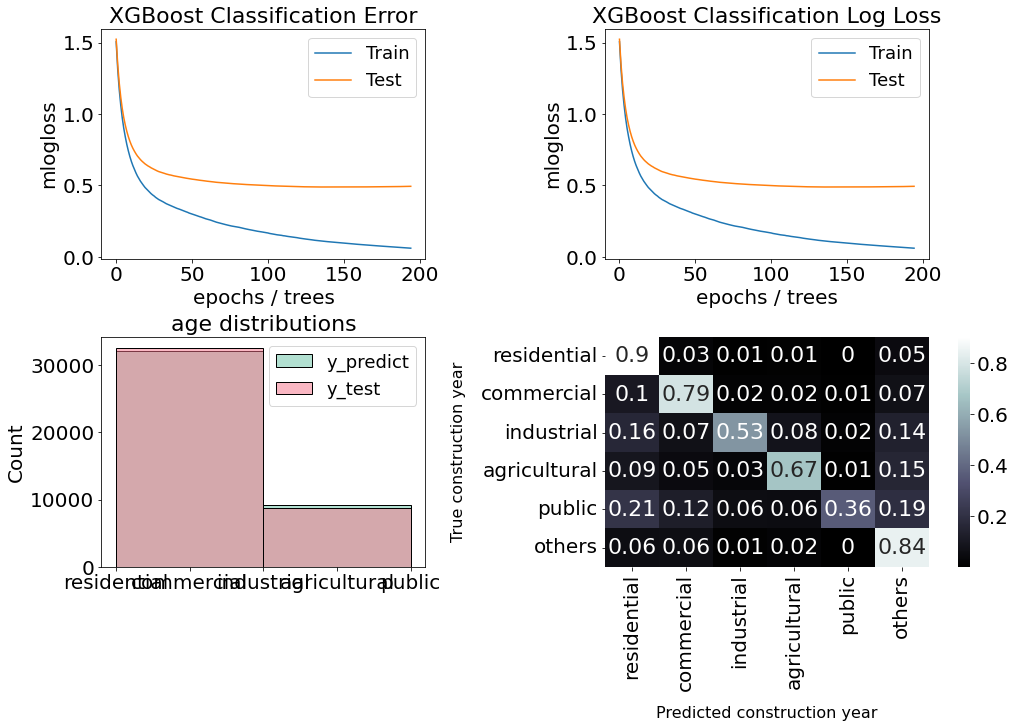

,importance
address_count,0.087
poi_n_within_buffer_0.02km2,0.050
address_total_count_within_buffer_0.92km2,0.027
bldg_footprint_area,0.019
satclip_pc3,0.017
address_distance,0.017
floors,0.016
poi_distance_industrial,0.016
poi_distance_non_residential,0.015
address_avg_count_within_buffer_0.92km2,0.015


In [16]:
model_dir = Path('/p/projects/eubucco/data/6-prediction-models')

for i in range(10):
    print(f'Training model with seed {i}...')
    dataset.GLOBAL_REPRODUCIBILITY_SEED = i
    predictor = TypeClassifier(
        model=XGBClassifier(**XGBOOST_PARAMS),
        df=df,
        frac=0.2,
        feature_cols=dataset.FEATURES_TYPE,
        test_training_split=pp.split_by_existing_split,
        preprocessing_stages=[
            pp.drop_type_ground_truth_features,
            pp.fill_block_na_with_bldg_features,
            pp.drop_na_cols,
        ],
        predict_confidence=True,
        early_stopping=True,
        mitigate_class_imbalance=True,
        labels=dataset.TYPE_LABELS,
        label_groups=[['residential'], ['commercial', 'industrial', 'public', 'agricultural', 'others']],
        hyperparameters=CLASS_HYPERPARAMETERS,
    )
    predictor.save_model(model_dir / f'type_EU_{i}.json')
    predictor.print_model_error()

predictor.evaluate()
ft_gain(predictor.model).head(30).round(3)


2025-12-19 11:54:48,366 | INFO : Model saved to /p/projects/eubucco/data/6-prediction-models/type_EU_0.json.
2025-12-19 11:54:48,506 | INFO : Calibrated model saved to /p/projects/eubucco/data/6-prediction-models/type_EU_0.calibration.joblib.


Classification report:
               precision    recall  f1-score  support
residential    0.945864  0.911985  0.928615   148917
commercial     0.755496  0.829891  0.790948    35777
industrial     0.604229  0.628323  0.616040     8050
agricultural   0.640744  0.740647  0.687083    11814
public         0.667433  0.583015  0.622375     4981
others         0.786705  0.791717  0.789203    43633
accuracy       0.856169  0.856169  0.856169        0
macro avg      0.733412  0.747596  0.739044   253172
weighted avg   0.860953  0.856169  0.857899   253172
Cohen’s kappa: 0.7645
Matthews correlation coefficient (MCC): 0.7650


FixedFormatter should only be used together with FixedLocator


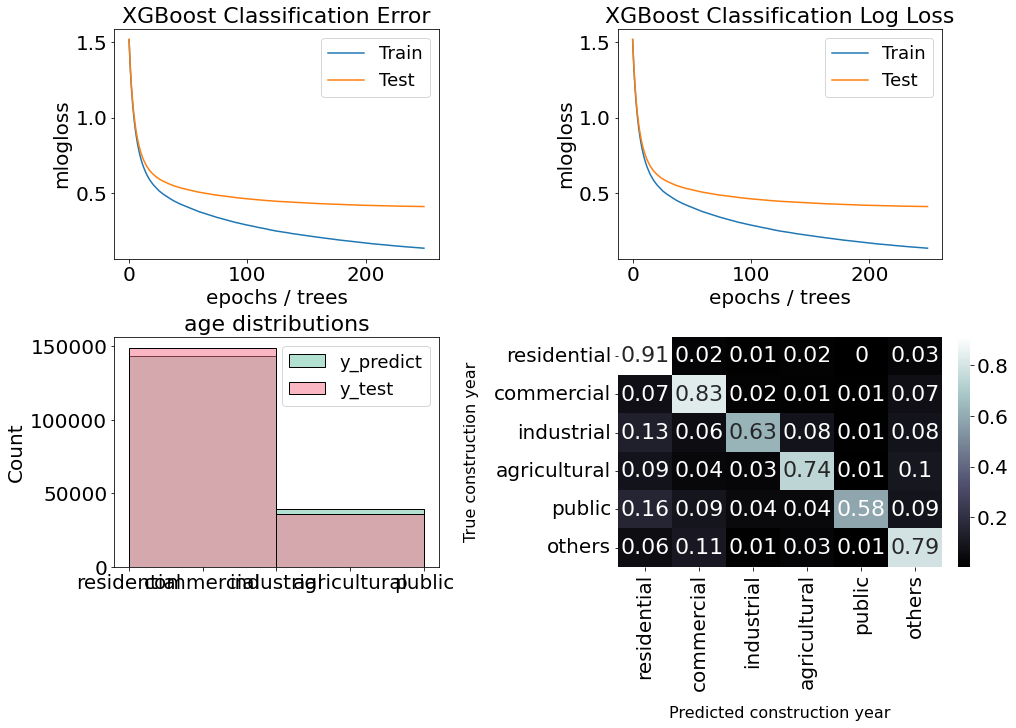

,importance
poi_n_within_buffer_0.02km2,0.054
ghs_closest_height_pooled_10,0.033
satclip_pc19,0.030
bldg_footprint_area,0.027
poi_distance_industrial,0.024
floors,0.022
height,0.020
satclip_pc3,0.018
address_total_count_within_buffer_0.92km2,0.017
bldg_area_perimeter_ratio,0.015


In [ ]:
model_dir = Path('/p/projects/eubucco/data/6-prediction-models')

for i in range(10):
    print(f'Training model with seed {i}...')
    dataset.GLOBAL_REPRODUCIBILITY_SEED = i
    predictor = TypeClassifier(
        model=XGBClassifier(**XGBOOST_PARAMS),
        df=df,
        frac=0.2,
        feature_cols=dataset.FEATURES_TYPE,
        test_training_split=pp.split_by_existing_split,
        preprocessing_stages=[
            pp.drop_type_ground_truth_features,
            pp.fill_block_na_with_bldg_features,
            pp.drop_na_cols,
        ],
        predict_confidence=True,
        early_stopping=True,
        mitigate_class_imbalance=True,
        labels=dataset.TYPE_LABELS,
        label_groups=[['residential'], ['commercial', 'industrial', 'public', 'agricultural', 'others']],
        hyperparameters=CLASS_HYPERPARAMETERS,
    )
    predictor.save_model(model_dir / f'type_EU_{i}.json')
    predictor.print_model_error()

predictor.evaluate()
ft_gain(predictor.model).head(30).round(3)


## EU-wide residential type estimation

In [17]:
gdf = pd.read_parquet('/p/projects/eubucco/data/5-feature-engineering/residential_type_generalization_dataset_eu_wide.parquet')

2026-01-23 04:43:06,006 | INFO : Dataset length original: 656697
2026-01-23 04:43:06,086 | INFO : Dataset length after dropping duplicates: 275495
2026-01-23 04:43:06,133 | INFO : Dataset length after dropping NaNs: 275495


Training model with seed 0...
['apartment block', 'detached single-family house', 'terraced house', 'semi-detached duplex house']


2026-01-23 04:43:06,229 | INFO : Dataset allocated memory: 205 MB
2026-01-23 04:43:06,276 | INFO : Dataset length after dropping building types excluded from classification: 275495
2026-01-23 04:43:06,278 | INFO : Dataset allocated memory: 205 MB
2026-01-23 04:43:06,346 | INFO : No abort signal received. Continuing... To abort please create /p/projects/eubucco/ufo-prediction/metadata/6445160-032e5196.abort.
2026-01-23 04:43:06,347 | INFO : Training dataset length: 220327
2026-01-23 04:43:06,347 | INFO : Test dataset length: 55168
2026-01-23 04:43:06,756 | INFO : Training dataset length after preprocessing: 220327
2026-01-23 04:43:06,757 | INFO : Test dataset length after preprocessing: 55168
A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
2026-01-23 04:43:45,826 | INFO : Model saved to /p/projects/eubucco/data/6-prediction-models/residential_type_EU_0.json.
2026-01-23 04:43:45,869 | INFO : Calibrated m

Classification report:
                               precision    recall  f1-score  support
apartment block                0.835539  0.862486  0.848799     4465
detached single-family house   0.987185  0.983217  0.985197    46773
terraced house                 0.874258  0.863539  0.868866     1876
semi-detached duplex house     0.843942  0.871470  0.857485     2054
accuracy                       0.965215  0.965215  0.965215        0
macro avg                      0.885231  0.895178  0.890087    55168
weighted avg                   0.965738  0.965215  0.965447    55168
Cohen’s kappa: 0.8734
Matthews correlation coefficient (MCC): 0.8735
Training model with seed 1...
['apartment block', 'detached single-family house', 'terraced house', 'semi-detached duplex house']


2026-01-23 04:43:46,238 | INFO : Dataset length after dropping building types excluded from classification: 275495
2026-01-23 04:43:46,242 | INFO : Dataset allocated memory: 205 MB
2026-01-23 04:43:46,303 | INFO : No abort signal received. Continuing... To abort please create /p/projects/eubucco/ufo-prediction/metadata/6445160-dcd70a4f.abort.
2026-01-23 04:43:46,304 | INFO : Training dataset length: 220327
2026-01-23 04:43:46,304 | INFO : Test dataset length: 55168
2026-01-23 04:43:46,703 | INFO : Training dataset length after preprocessing: 220327
2026-01-23 04:43:46,704 | INFO : Test dataset length after preprocessing: 55168
A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
2026-01-23 04:44:25,041 | INFO : Model saved to /p/projects/eubucco/data/6-prediction-models/residential_type_EU_1.json.
2026-01-23 04:44:25,080 | INFO : Calibrated model saved to /p/projects/eubucco/data/6-prediction-models/residen

...

2026-01-23 04:48:20,318 | INFO : Dataset length after dropping building types excluded from classification: 275495
2026-01-23 04:48:20,322 | INFO : Dataset allocated memory: 205 MB
2026-01-23 04:48:20,389 | INFO : No abort signal received. Continuing... To abort please create /p/projects/eubucco/ufo-prediction/metadata/6445160-cd673d0e.abort.
2026-01-23 04:48:20,389 | INFO : Training dataset length: 220327
2026-01-23 04:48:20,389 | INFO : Test dataset length: 55168
2026-01-23 04:48:20,776 | INFO : Training dataset length after preprocessing: 220327
2026-01-23 04:48:20,777 | INFO : Test dataset length after preprocessing: 55168
A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
2026-01-23 04:48:58,912 | INFO : Model saved to /p/projects/eubucco/data/6-prediction-models/residential_type_EU_8.json.
2026-01-23 04:48:58,950 | INFO : Calibrated model saved to /p/projects/eubucco/data/6-prediction-models/residen

Classification report:
                               precision    recall  f1-score  support
apartment block                0.835682  0.863382  0.849306     4465
detached single-family house   0.987231  0.983516  0.985370    46773
terraced house                 0.881421  0.859808  0.870480     1876
semi-detached duplex house     0.842575  0.872931  0.857484     2054
accuracy                       0.965469  0.965469  0.965469        0
macro avg                      0.886727  0.894909  0.890660    55168
weighted avg                   0.965981  0.965469  0.965689    55168
Cohen’s kappa: 0.8742
Matthews correlation coefficient (MCC): 0.8743
Training model with seed 9...
['apartment block', 'detached single-family house', 'terraced house', 'semi-detached duplex house']


2026-01-23 04:48:59,295 | INFO : Dataset allocated memory: 205 MB
2026-01-23 04:48:59,356 | INFO : No abort signal received. Continuing... To abort please create /p/projects/eubucco/ufo-prediction/metadata/6445160-5c8ef9f7.abort.
2026-01-23 04:48:59,356 | INFO : Training dataset length: 220327
2026-01-23 04:48:59,356 | INFO : Test dataset length: 55168
2026-01-23 04:48:59,745 | INFO : Training dataset length after preprocessing: 220327
2026-01-23 04:48:59,746 | INFO : Test dataset length after preprocessing: 55168
A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
2026-01-23 04:49:38,828 | INFO : Model saved to /p/projects/eubucco/data/6-prediction-models/residential_type_EU_9.json.
2026-01-23 04:49:38,867 | INFO : Calibrated model saved to /p/projects/eubucco/data/6-prediction-models/residential_type_EU_9.calibration.joblib.


Classification report:
                               precision    recall  f1-score  support
apartment block                0.837592  0.866293  0.851701     4465
detached single-family house   0.987211  0.983644  0.985425    46773
terraced house                 0.879151  0.860874  0.869917     1876
semi-detached duplex house     0.844002  0.866602  0.855153     2054
accuracy                       0.965614  0.965614  0.965614        0
macro avg                      0.886989  0.894353  0.890549    55168
weighted avg                   0.966095  0.965614  0.965824    55168
Cohen’s kappa: 0.8747
Matthews correlation coefficient (MCC): 0.8748
Classification report:
                               precision    recall  f1-score  support
apartment block                0.837592  0.866293  0.851701     4465
detached single-family house   0.987211  0.983644  0.985425    46773
terraced house                 0.879151  0.860874  0.869917     1876
semi-detached duplex house     0.844002  0.866602  0.85

FixedFormatter should only be used together with FixedLocator


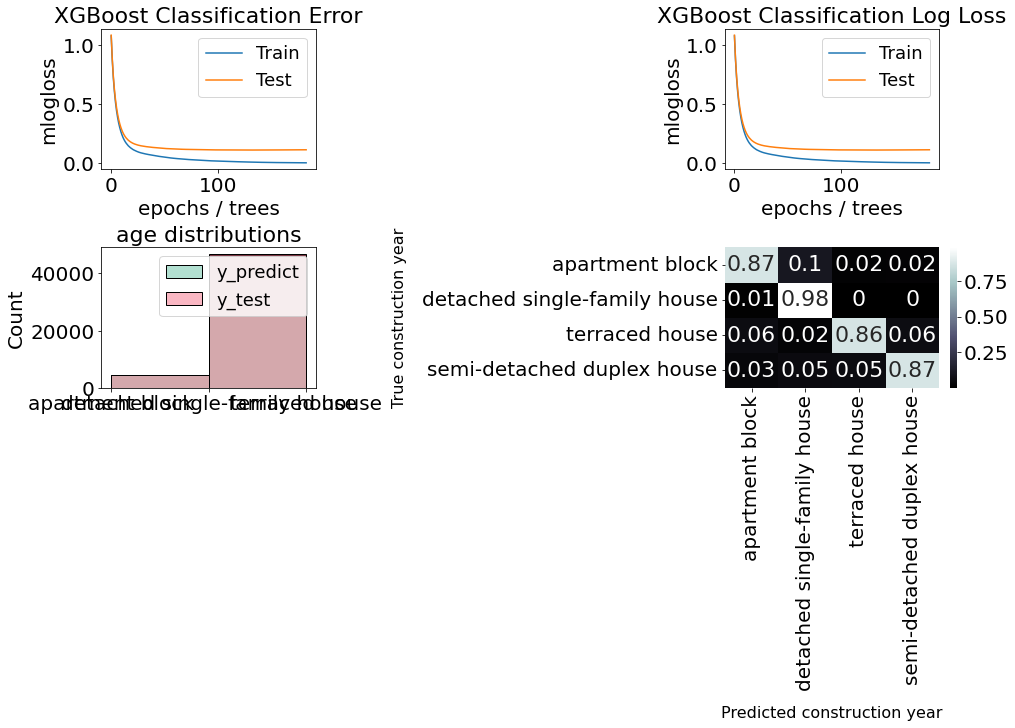

,importance
block_length,0.202
block_diff_std_footprint_area,0.049
block_footprint_area,0.046
block_avg_footprint_area,0.046
height,0.045
block_diff_std_orientation,0.044
bldg_area_perimeter_ratio,0.038
block_area_perimeter_ratio,0.028
ghs_closest_height_pooled_10,0.028
cdd,0.027


In [18]:
model_dir = Path('/p/projects/eubucco/data/6-prediction-models')

for i in range(10):
    print(f'Training model with seed {i}...')
    dataset.GLOBAL_REPRODUCIBILITY_SEED = i
    predictor = TypeClassifier(
        model=XGBClassifier(**XGBOOST_PARAMS),
        target_attribute='residential_type',
        df=gdf,
        feature_cols=dataset.FEATURES_RES_TYPE,
        test_training_split=pp.split_by_existing_split,
        preprocessing_stages=[
            pp.drop_type_ground_truth_features,
            pp.fill_block_na_with_bldg_features,
            pp.drop_na_cols,
        ],
        labels=dataset.RES_TYPE_LABELS,
        predict_confidence=True,
        early_stopping=True,
        mitigate_class_imbalance=True,
        hyperparameters=CLASS_HYPERPARAMETERS,
    )
    predictor.save_model(model_dir / f'residential_type_EU_{i}.json')
    predictor.print_model_error()

predictor.evaluate()
ft_gain(predictor.model).head(30).round(3)

2025-12-19 12:05:12,799 | INFO : Model saved to /p/projects/eubucco/data/6-prediction-models/residential_type_EU_0.json.
2025-12-19 12:05:12,883 | INFO : Calibrated model saved to /p/projects/eubucco/data/6-prediction-models/residential_type_EU_0.calibration.joblib.


Classification report:
                               precision    recall  f1-score  support
apartment block                0.894926  0.904613  0.899744    17644
detached single-family house   0.982639  0.978277  0.980453    90317
terraced house                 0.881598  0.875102  0.878338     8551
semi-detached duplex house     0.908286  0.925107  0.916619    14741
accuracy                       0.955681  0.955681  0.955681        0
macro avg                      0.916862  0.920775  0.918788   131253
weighted avg                   0.955915  0.955681  0.955782   131253
Cohen’s kappa: 0.9102
Matthews correlation coefficient (MCC): 0.9102


FixedFormatter should only be used together with FixedLocator


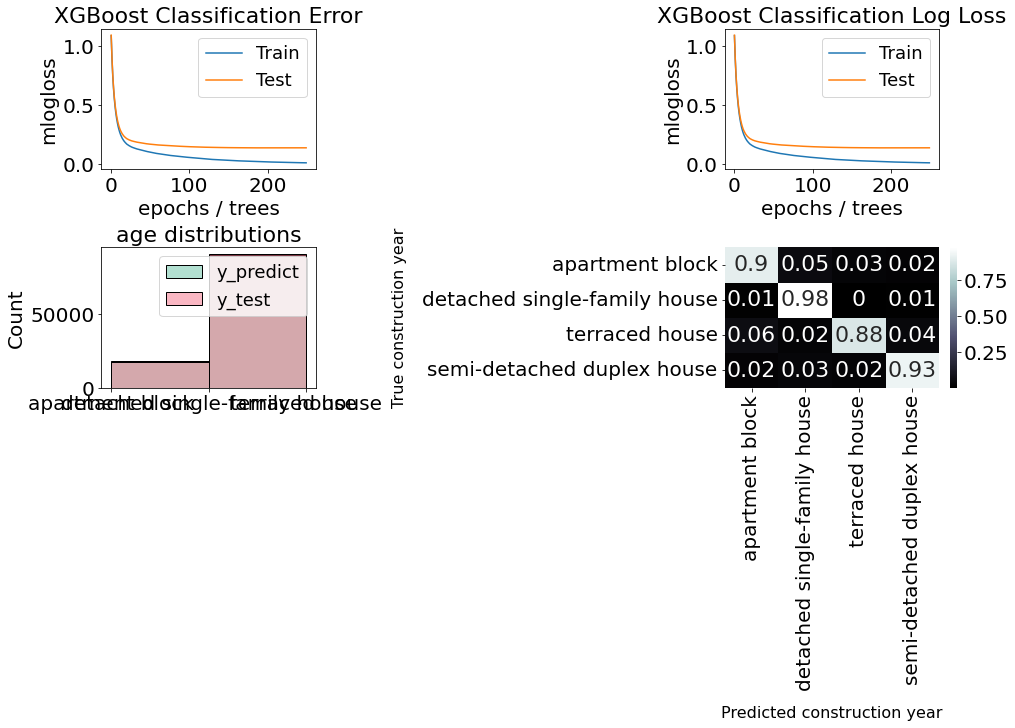

,importance
block_length,0.072
ghs_closest_height_pooled_10,0.059
height,0.053
cdd,0.043
block_longest_axis_length,0.039
block_diff_std_footprint_area,0.038
block_avg_footprint_area,0.037
floors,0.036
bldg_touches,0.036
bldg_footprint_area,0.033


In [ ]:
model_dir = Path('/p/projects/eubucco/data/6-prediction-models')

for i in range(10):
    print(f'Training model with seed {i}...')
    dataset.GLOBAL_REPRODUCIBILITY_SEED = i
    predictor = TypeClassifier(
        model=XGBClassifier(**XGBOOST_PARAMS),
        target_attribute='residential_type',
        df=gdf,
        feature_cols=dataset.FEATURES_RES_TYPE,
        test_training_split=pp.split_by_existing_split,
        preprocessing_stages=[
            # pp.drop_type_ground_truth_features,
            pp.fill_block_na_with_bldg_features,
            pp.drop_na_cols,
        ],
        labels=dataset.RES_TYPE_LABELS,
        predict_confidence=True,
        early_stopping=True,
        mitigate_class_imbalance=True,
        hyperparameters=CLASS_HYPERPARAMETERS,
    )
    predictor.save_model(model_dir / f'residential_type_EU_{i}.json')
    predictor.print_model_error()

predictor.evaluate()
ft_gain(predictor.model).head(30).round(3)

## EU-wide height estimation

In [ ]:
data_path = Path('/p/projects/eubucco/data/5-feature-engineering')
df_height = pd.read_parquet(data_path / 'height_generalization_dataset_eu_wide.parquet')

2026-01-23 04:15:40,674 | INFO : Dataset length original: 6156236


Training model with seed 0...


2026-01-23 04:15:41,240 | INFO : Dataset length after dropping duplicates: 597663
2026-01-23 04:15:41,370 | INFO : Dataset length after dropping NaNs: 597663
2026-01-23 04:15:41,374 | INFO : Dataset allocated memory: 767 MB
2026-01-23 04:15:41,550 | INFO : No abort signal received. Continuing... To abort please create /p/projects/eubucco/ufo-prediction/metadata/6445160-475c88ad.abort.
2026-01-23 04:15:41,553 | INFO : Dataset standard deviation: 4.376622893068081
2026-01-23 04:15:41,553 | INFO : Dataset average height: 5.079562174231658
2026-01-23 04:15:41,554 | INFO : Training dataset length: 505427
2026-01-23 04:15:41,554 | INFO : Test dataset length: 92236
2026-01-23 04:15:42,510 | WARNING : Missing columns {'ghs_height_buffer_100', 'nuts_coast_type', 'poi_n_within_buffer_0.02km2', 'distance_to_center'}. Proceeding with available columns.
2026-01-23 04:15:42,599 | INFO : Test dataset standard deviation after preprocessing: 3.979349315492931
2026-01-23 04:15:42,600 | INFO : Test avera

MAE: 1.43 y
RMSE: 2.43 y
R2: 0.6280


2026-01-23 04:15:58,781 | INFO : Model saved to /p/projects/eubucco/data/6-prediction-models/height_EU_0.json.
2026-01-23 04:15:58,781 | INFO : Dataset length original: 6156236


...

MAE: 1.43 y
RMSE: 2.42 y
R2: 0.6295


2026-01-23 04:18:20,131 | INFO : Model saved to /p/projects/eubucco/data/6-prediction-models/height_EU_8.json.
2026-01-23 04:18:20,132 | INFO : Dataset length original: 6156236


Training model with seed 9...


2026-01-23 04:18:20,427 | INFO : Dataset length after dropping duplicates: 597663
2026-01-23 04:18:20,558 | INFO : Dataset length after dropping NaNs: 597663
2026-01-23 04:18:20,562 | INFO : Dataset allocated memory: 767 MB
2026-01-23 04:18:20,753 | INFO : No abort signal received. Continuing... To abort please create /p/projects/eubucco/ufo-prediction/metadata/6445160-ac3aa563.abort.
2026-01-23 04:18:20,755 | INFO : Dataset standard deviation: 4.376622893068081
2026-01-23 04:18:20,756 | INFO : Dataset average height: 5.079562174231658
2026-01-23 04:18:20,756 | INFO : Training dataset length: 505427
2026-01-23 04:18:20,756 | INFO : Test dataset length: 92236
2026-01-23 04:18:21,739 | WARNING : Missing columns {'ghs_height_buffer_100', 'nuts_coast_type', 'poi_n_within_buffer_0.02km2', 'distance_to_center'}. Proceeding with available columns.
2026-01-23 04:18:21,827 | INFO : Test dataset standard deviation after preprocessing: 3.979349315492931
2026-01-23 04:18:21,828 | INFO : Test avera

MAE: 1.43 y
RMSE: 2.44 y
R2: 0.6250
MAE: 1.43 y
RMSE: 2.44 y
R2: 0.6250


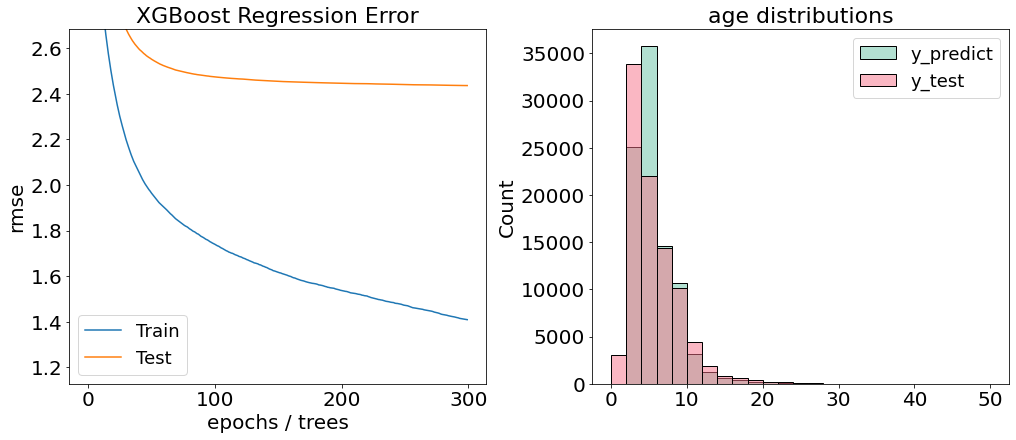

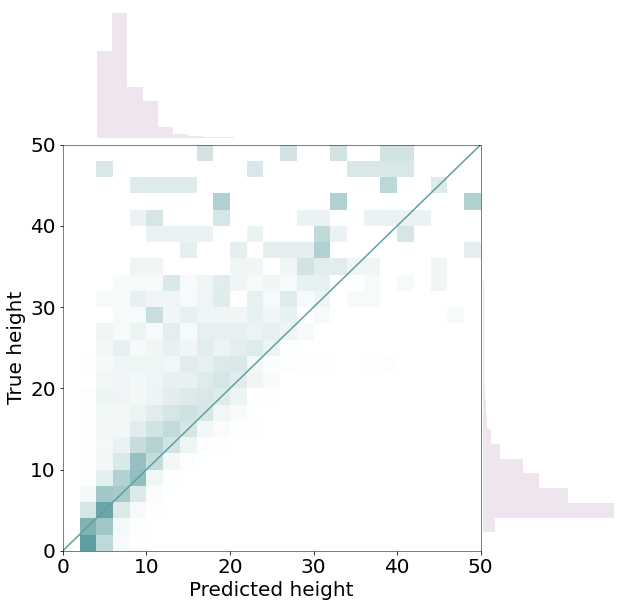

,importance
bldg_footprint_area,0.080816
bldg_area_perimeter_ratio,0.077310
bldg_msft_height,0.047405
hdd,0.040161
bldg_perimeter,0.035733
cdd,0.034317
floors,0.024164
bldg_corners_area_ratio,0.023309
address_count,0.019545
poi_n_within_buffer_0.92km2,0.018579


In [12]:
model_dir = Path('/p/projects/eubucco/data/6-prediction-models')

for i in range(10):
    print(f'Training model with seed {i}...')
    dataset.GLOBAL_REPRODUCIBILITY_SEED = i
    predictor = HeightPredictor(
        model=XGBRegressor(**XGBOOST_PARAMS),
        df=df_height,
        feature_cols=dataset.FEATURES_HEIGHT,
        # cross_validation_split=pp.cross_validation,
        test_training_split=pp.split_by_existing_split,
        # test_training_split=pp.split_by_country,
        # test_training_split=pp.split_by_h3_cell,
        # test_training_split=pp.split_80_20,
        preprocessing_stages=[pp.drop_microsoft_bldgs, pp.remove_height_outliers, pp.drop_height_ground_truth_features, pp.fill_block_na_with_bldg_features, pp.drop_na_cols],
        hyperparameters=REG_HYPERPARAMETERS,
    )
    predictor.print_model_error()
    predictor.save_model(model_dir / f'height_EU_{i}.json')

predictor.evaluate_regression()
ft_gain(predictor.model).head(20)

In [90]:
# df_floors[df_floors['height'] < 0][['floors', 'height', 'id', 'dataset', 'validation']]
df_floors[df_floors['floors'] > df_floors['height'] / 1.5][['floors', 'height', 'id', 'dataset']].sort_values(by='floors', ascending=False)

,floors,height,id,dataset
809911,24.0,32.8,v1.0-SI050-18915,gov
766369,22.0,5.0,v1.0-HR01333-4396,osm
800753,21.0,29.4,v1.0-SI061-62209,gov
306629,15.0,15.0,v1.0-BGRSE27-31,osm
804928,14.0,13.9,v1.0-SI190-7311,gov
...,...,...,...,...
447624,1.0,1.1,v1.0-FR27643-744,gov
384128,1.0,0.5,v1.0-FR07261-398,gov
725956,1.0,0.3,v1.0-FR92048-2501,gov
495775,1.0,1.1,v1.0-FR37018-962,gov


## EU-wide floor estimation

In [13]:
data_path = Path('/p/projects/eubucco/data/5-feature-engineering')
df_height = pd.read_parquet(data_path / 'height_generalization_dataset_eu_wide.parquet')
df_floors = df_height.dropna(subset='floors')

2026-01-23 04:19:49,615 | INFO : Dataset length original: 814013
2026-01-23 04:19:49,733 | INFO : Dataset length after dropping duplicates: 276727
2026-01-23 04:19:49,806 | INFO : Dataset length after dropping NaNs: 276727
2026-01-23 04:19:49,810 | INFO : Dataset allocated memory: 355 MB


Training model with seed 0...


2026-01-23 04:19:49,905 | INFO : No abort signal received. Continuing... To abort please create /p/projects/eubucco/ufo-prediction/metadata/6445160-e6e1210f.abort.
2026-01-23 04:19:49,907 | INFO : Dataset standard deviation: 1.048943498413959
2026-01-23 04:19:49,907 | INFO : Dataset average # of floors: 1.7049077249419102
2026-01-23 04:19:49,907 | INFO : Training dataset length: 221420
2026-01-23 04:19:49,907 | INFO : Test dataset length: 55307
2026-01-23 04:19:50,373 | WARNING : Missing columns {'ghs_height_buffer_100', 'nuts_coast_type', 'poi_n_within_buffer_0.02km2', 'distance_to_center'}. Proceeding with available columns.
2026-01-23 04:19:50,412 | INFO : Test dataset standard deviation after preprocessing: 1.0554707453675527
2026-01-23 04:19:50,413 | INFO : Test average # of floors after preprocessing: 1.703075560055689
2026-01-23 04:19:50,413 | INFO : Training dataset length after preprocessing: 218146
2026-01-23 04:19:50,413 | INFO : Test dataset length after preprocessing: 5530

MAE: 0.23 y
RMSE: 0.44 y
R2: 0.8278
Training model with seed 1...


2026-01-23 04:19:57,909 | INFO : No abort signal received. Continuing... To abort please create /p/projects/eubucco/ufo-prediction/metadata/6445160-d7521c75.abort.
2026-01-23 04:19:57,911 | INFO : Dataset standard deviation: 1.048943498413959
2026-01-23 04:19:57,911 | INFO : Dataset average # of floors: 1.7049077249419102
2026-01-23 04:19:57,911 | INFO : Training dataset length: 221420
2026-01-23 04:19:57,912 | INFO : Test dataset length: 55307
2026-01-23 04:19:58,350 | WARNING : Missing columns {'ghs_height_buffer_100', 'nuts_coast_type', 'poi_n_within_buffer_0.02km2', 'distance_to_center'}. Proceeding with available columns.
2026-01-23 04:19:58,385 | INFO : Test dataset standard deviation after preprocessing: 1.0554707453675527
2026-01-23 04:19:58,385 | INFO : Test average # of floors after preprocessing: 1.703075560055689
2026-01-23 04:19:58,386 | INFO : Training dataset length after preprocessing: 218146
2026-01-23 04:19:58,386 | INFO : Test dataset length after preprocessing: 5530

...

MAE: 0.23 y
RMSE: 0.44 y
R2: 0.8263
Training model with seed 8...


2026-01-23 04:20:54,212 | INFO : No abort signal received. Continuing... To abort please create /p/projects/eubucco/ufo-prediction/metadata/6445160-28f9f7d8.abort.
2026-01-23 04:20:54,214 | INFO : Dataset standard deviation: 1.048943498413959
2026-01-23 04:20:54,215 | INFO : Dataset average # of floors: 1.7049077249419102
2026-01-23 04:20:54,215 | INFO : Training dataset length: 221420
2026-01-23 04:20:54,215 | INFO : Test dataset length: 55307
2026-01-23 04:20:54,659 | WARNING : Missing columns {'ghs_height_buffer_100', 'nuts_coast_type', 'poi_n_within_buffer_0.02km2', 'distance_to_center'}. Proceeding with available columns.
2026-01-23 04:20:54,705 | INFO : Test dataset standard deviation after preprocessing: 1.0554707453675527
2026-01-23 04:20:54,705 | INFO : Test average # of floors after preprocessing: 1.703075560055689
2026-01-23 04:20:54,705 | INFO : Training dataset length after preprocessing: 218146
2026-01-23 04:20:54,705 | INFO : Test dataset length after preprocessing: 5530

MAE: 0.23 y
RMSE: 0.44 y
R2: 0.8271
Training model with seed 9...


2026-01-23 04:21:02,522 | INFO : No abort signal received. Continuing... To abort please create /p/projects/eubucco/ufo-prediction/metadata/6445160-558fde48.abort.
2026-01-23 04:21:02,523 | INFO : Dataset standard deviation: 1.048943498413959
2026-01-23 04:21:02,524 | INFO : Dataset average # of floors: 1.7049077249419102
2026-01-23 04:21:02,524 | INFO : Training dataset length: 221420
2026-01-23 04:21:02,524 | INFO : Test dataset length: 55307
2026-01-23 04:21:02,979 | WARNING : Missing columns {'ghs_height_buffer_100', 'nuts_coast_type', 'poi_n_within_buffer_0.02km2', 'distance_to_center'}. Proceeding with available columns.
2026-01-23 04:21:03,032 | INFO : Test dataset standard deviation after preprocessing: 1.0554707453675527
2026-01-23 04:21:03,033 | INFO : Test average # of floors after preprocessing: 1.703075560055689
2026-01-23 04:21:03,033 | INFO : Training dataset length after preprocessing: 218146
2026-01-23 04:21:03,033 | INFO : Test dataset length after preprocessing: 5530

MAE: 0.23 y
RMSE: 0.44 y
R2: 0.8260
MAE: 0.23 y
RMSE: 0.44 y
R2: 0.8260


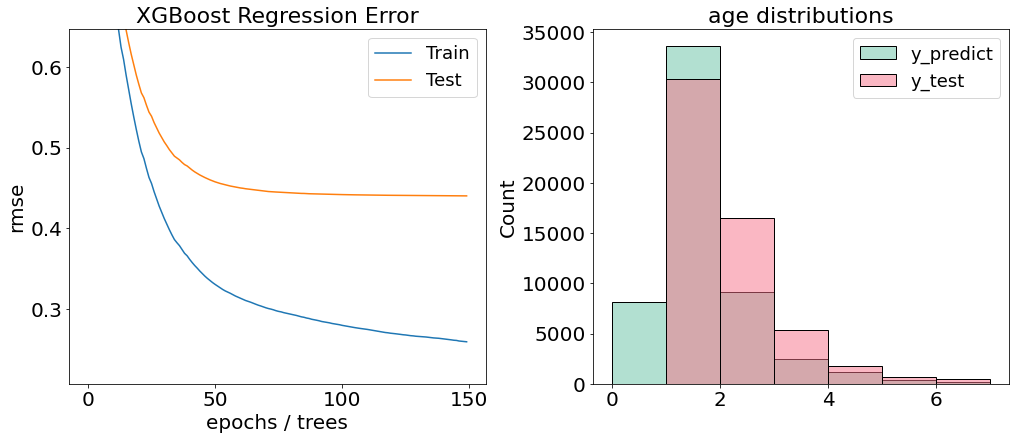

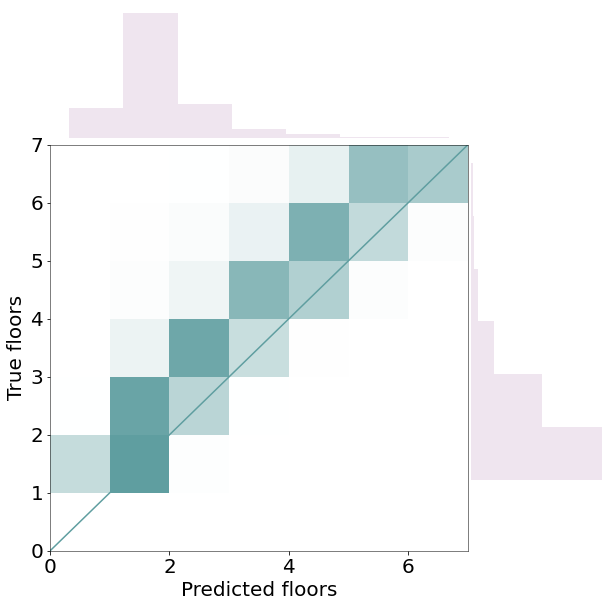

,importance
height,0.205413
bldg_msft_height,0.116029
type,0.115732
satclip_pc25,0.064275
hdd,0.033919
bldg_footprint_area,0.031099
address_count,0.018517
address_diff_std_count_within_buffer_0.92km2,0.017763
bldg_area_perimeter_ratio,0.017375
block_area_perimeter_ratio,0.014359


In [14]:
model_dir = Path('/p/projects/eubucco/data/6-prediction-models')

for i in range(10):
    print(f'Training model with seed {i}...')
    dataset.GLOBAL_REPRODUCIBILITY_SEED = i
        
    predictor = FloorsPredictor(
        model=XGBRegressor(**XGBOOST_PARAMS),
        df=df_floors,
        hyperparameters={**REG_HYPERPARAMETERS, **{'n_estimators': 150}},
        feature_cols=dataset.FEATURES_FLOORS,
        test_training_split=pp.split_by_existing_split,
        preprocessing_stages=[
            pp.drop_floors_ground_truth_features,
            pp.remove_floors_outliers,
            pp.fill_block_na_with_bldg_features,
            pp.drop_na_cols,
        ],
    )
    predictor.save_model(model_dir / f'floors_EU_{i}.json')
    predictor.print_model_error()

predictor.evaluate_regression()
ft_gain(predictor.model).head(20)

In [17]:
data_path = Path('/p/projects/eubucco/data/5-feature-engineering-extra')
df_floors = pd.read_parquet(data_path / 'floors_generalization_dataset_eu_wide.parquet')

2026-02-06 17:52:04,627 | INFO : Dataset length original: 1961362
2026-02-06 17:52:04,748 | INFO : Dataset length after dropping duplicates: 402382


Training model with seed 0...


2026-02-06 17:52:04,858 | INFO : Dataset length after dropping NaNs: 402382
2026-02-06 17:52:04,860 | INFO : Dataset allocated memory: 277 MB
2026-02-06 17:52:04,936 | INFO : No abort signal received. Continuing... To abort please create /p/projects/eubucco/ufo-prediction/metadata/6821561-ea996885.abort.
2026-02-06 17:52:04,938 | INFO : Dataset standard deviation: 1.1241442945270292
2026-02-06 17:52:04,939 | INFO : Dataset average # of floors: 1.6528838268113384
2026-02-06 17:52:04,939 | INFO : Training dataset length: 321841
2026-02-06 17:52:04,939 | INFO : Test dataset length: 80541
2026-02-06 17:52:05,301 | WARNING : Missing columns {'nuts_coast_type'}. Proceeding with available columns.
2026-02-06 17:52:05,356 | INFO : Test dataset standard deviation after preprocessing: 1.1050634320432497
2026-02-06 17:52:05,356 | INFO : Test average # of floors after preprocessing: 1.6480438534411046
2026-02-06 17:52:05,356 | INFO : Training dataset length after preprocessing: 321841
2026-02-06 1

MAE: 0.36 y
RMSE: 0.63 y
R2: 0.6791
Training model with seed 1...


2026-02-06 17:52:15,869 | INFO : Dataset length after dropping NaNs: 402382
2026-02-06 17:52:15,873 | INFO : Dataset allocated memory: 277 MB
2026-02-06 17:52:15,933 | INFO : No abort signal received. Continuing... To abort please create /p/projects/eubucco/ufo-prediction/metadata/6821561-45734093.abort.
2026-02-06 17:52:15,934 | INFO : Dataset standard deviation: 1.1241442945270292
2026-02-06 17:52:15,935 | INFO : Dataset average # of floors: 1.6528838268113384
2026-02-06 17:52:15,935 | INFO : Training dataset length: 321841
2026-02-06 17:52:15,935 | INFO : Test dataset length: 80541
2026-02-06 17:52:16,275 | WARNING : Missing columns {'nuts_coast_type'}. Proceeding with available columns.
2026-02-06 17:52:16,318 | INFO : Test dataset standard deviation after preprocessing: 1.1050634320432497
2026-02-06 17:52:16,319 | INFO : Test average # of floors after preprocessing: 1.6480438534411046
2026-02-06 17:52:16,319 | INFO : Training dataset length after preprocessing: 321841
2026-02-06 1

...

MAE: 0.36 y
RMSE: 0.63 y
R2: 0.6769
Training model with seed 8...


2026-02-06 17:53:33,023 | INFO : Dataset length after dropping NaNs: 402382
2026-02-06 17:53:33,025 | INFO : Dataset allocated memory: 277 MB
2026-02-06 17:53:33,101 | INFO : No abort signal received. Continuing... To abort please create /p/projects/eubucco/ufo-prediction/metadata/6821561-42f74f72.abort.
2026-02-06 17:53:33,103 | INFO : Dataset standard deviation: 1.1241442945270292
2026-02-06 17:53:33,104 | INFO : Dataset average # of floors: 1.6528838268113384
2026-02-06 17:53:33,104 | INFO : Training dataset length: 321841
2026-02-06 17:53:33,104 | INFO : Test dataset length: 80541
2026-02-06 17:53:33,472 | WARNING : Missing columns {'nuts_coast_type'}. Proceeding with available columns.
2026-02-06 17:53:33,526 | INFO : Test dataset standard deviation after preprocessing: 1.1050634320432495
2026-02-06 17:53:33,527 | INFO : Test average # of floors after preprocessing: 1.6480438534411046
2026-02-06 17:53:33,527 | INFO : Training dataset length after preprocessing: 321841
2026-02-06 1

MAE: 0.36 y
RMSE: 0.63 y
R2: 0.6771
Training model with seed 9...


2026-02-06 17:53:44,138 | INFO : Dataset length after dropping NaNs: 402382
2026-02-06 17:53:44,140 | INFO : Dataset allocated memory: 277 MB
2026-02-06 17:53:44,215 | INFO : No abort signal received. Continuing... To abort please create /p/projects/eubucco/ufo-prediction/metadata/6821561-17d88f85.abort.
2026-02-06 17:53:44,217 | INFO : Dataset standard deviation: 1.1241442945270292
2026-02-06 17:53:44,218 | INFO : Dataset average # of floors: 1.6528838268113384
2026-02-06 17:53:44,218 | INFO : Training dataset length: 321841
2026-02-06 17:53:44,218 | INFO : Test dataset length: 80541
2026-02-06 17:53:44,586 | WARNING : Missing columns {'nuts_coast_type'}. Proceeding with available columns.
2026-02-06 17:53:44,642 | INFO : Test dataset standard deviation after preprocessing: 1.1050634320432495
2026-02-06 17:53:44,643 | INFO : Test average # of floors after preprocessing: 1.6480438534411046
2026-02-06 17:53:44,643 | INFO : Training dataset length after preprocessing: 321841
2026-02-06 1

MAE: 0.36 y
RMSE: 0.63 y
R2: 0.6774
MAE: 0.36 y
RMSE: 0.63 y
R2: 0.6774


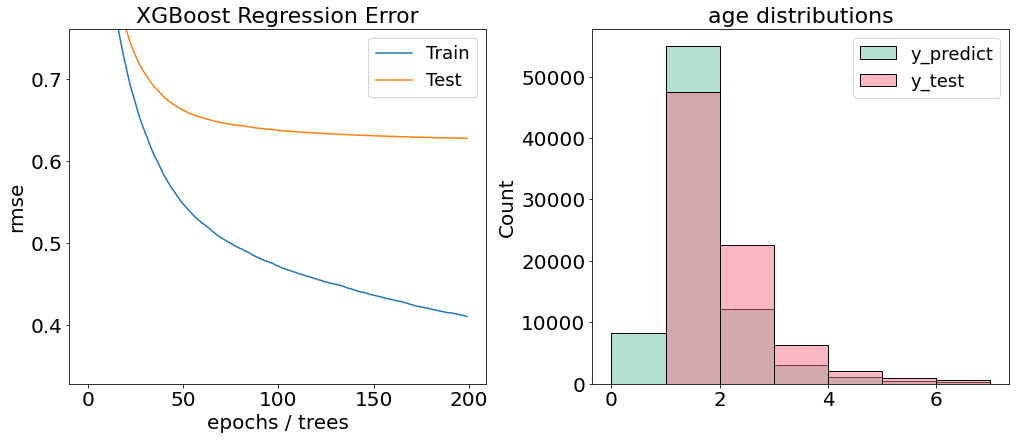

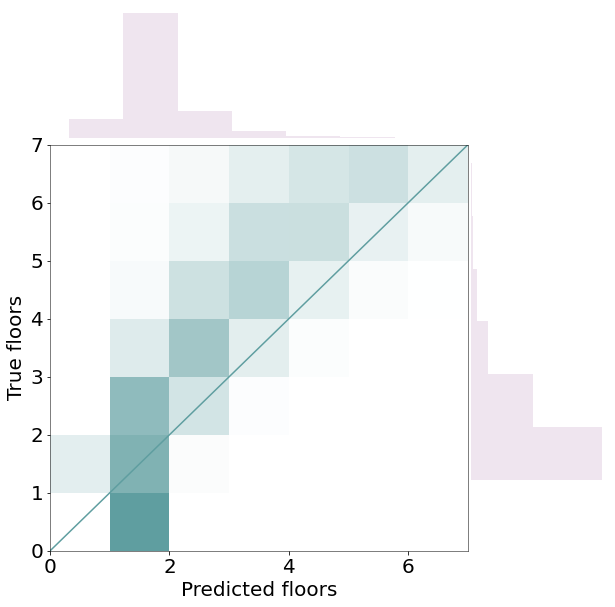

,importance
ghs_closest_height_pooled_5,0.076443
address_count,0.073905
type,0.054463
bldg_msft_height,0.051881
ghs_closest_height_pooled_10,0.047526
block_area_perimeter_ratio,0.037708
poi_n_within_buffer_0.92km2,0.034222
ghs_height_buffer_100,0.028393
block_footprint_area,0.027553
bldg_footprint_area,0.026659


In [ ]:
model_dir = Path('/p/projects/eubucco/data/6-prediction-models')

for i in range(10):
    print(f'Training model with seed {i}...')
    dataset.GLOBAL_REPRODUCIBILITY_SEED = i
        
    predictor = FloorsPredictor(
        model=XGBRegressor(**XGBOOST_PARAMS),
        df=df_floors,
        hyperparameters={**REG_HYPERPARAMETERS, **{'n_estimators': 200, 'colsample_bytree': 0.5}},
        feature_cols=dataset.FEATURES_FLOORS,
        test_training_split=pp.split_by_existing_split,
        preprocessing_stages=[
            pp.drop_floors_ground_truth_features,
            pp.fill_block_na_with_bldg_features,
            pp.drop_na_cols,
        ],
    )
    predictor.save_model(model_dir / f'floors_EU_{i}.json')
    predictor.print_model_error()

predictor.evaluate_regression()
ft_gain(predictor.model).head(20)